In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing

In [2]:
housing_data = fetch_california_housing()
features = pd.DataFrame(housing_data.data, columns=housing_data.feature_names)
target = pd.DataFrame(housing_data.target, columns=['Target'])
df = features.join(target)
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df[['MedInc','AveRooms','Target']])

In [4]:
df_scaled.shape

(20640, 3)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df_scaled[:10000, :2], 
    df_scaled[:10000, 2:], 
    test_size=0.33, 
    random_state=42
)

In [6]:
X_train.shape

(6700, 2)

In [7]:
class SimpleNeuralNetwork:
    
    def __init__(self): 
        
                
        # Initial weights and biases assigned random values ranging from 0 to 1. 
        # We have a total of 9 weights and 4 biases as shown in the figure above.
        
        # Weights
        self.w1, \
        self.w2, \
        self.w3, \
        self.w4, \
        self.w5, \
        self.w6, \
        self.w7, \
        self.w8, \
        self.w9 = np.random.rand(9)

        # Biases
        self.b_n1, \
        self.b_n2, \
        self.b_n3, \
        self.b_y_hat = np.random.rand(4) 

    # Activation functions for the neurons
    # sigmoid is for forward propagation, sigmoid derivative is for back propagation
    
    def sigmoid(self, x): return 1 / (1 + np.e**-x)
    def sigmoid_der(self, x): return self.sigmoid(x) * (1 - self.sigmoid(x))

    
    # Feedforward function produces result of the network prediction for each sample.

    def feedforward(self, x):

        # x[0], x[1] - features
        # n* - neurons in the hidden layer, y_hat - predicted value
        self.n1    = self.sigmoid(x[0]*self.w1 + x[1]*self.w2 + self.b_n1)
        self.n2    = self.sigmoid(x[0]*self.w3 + x[1]*self.w4 + self.b_n2)
        self.n3    = self.sigmoid(x[0]*self.w5 + x[1]*self.w6 + self.b_n3)
        self.y_hat = self.sigmoid(self.n1*self.w7 + self.n2*self.w8 + self.n3*self.w9 + self.b_y_hat)

    

    # Backpropagation updates all the weights and biases of the network.
    # By using Gradient Descent technique, each trainable parameter (weight or bias) is changing a little 
    # bit towards the minimum of MSE.
    # "output layer" => "hidden layer 2" => "hidden layer 1"
    
    def backpropagation(self, x, y):

        # We calculate some values here to use them later
        y_hat_der = (-2 * (y-self.y_hat) * self.sigmoid_der(self.n1*self.w7 + self.n2*self.w8 + self.n3*self.w9 + self.b_y_hat))
        n1_der = self.w7 * self.sigmoid_der(x[0]*self.w1 + x[1]*self.w2 + self.b_n1)
        n2_der = self.w8 * self.sigmoid_der(x[0]*self.w3 + x[1]*self.w4 + self.b_n2)
        n3_der = self.w9 * self.sigmoid_der(x[0]*self.w5 + x[1]*self.w6 + self.b_n3)

        # Biases
        self.b_n1    -= self.lr * y_hat_der * n1_der
        self.b_n2    -= self.lr * y_hat_der * n2_der
        self.b_n3    -= self.lr * y_hat_der * n3_der
        self.b_y_hat -= self.lr * y_hat_der

        # Weights
        self.w7 -= self.lr * y_hat_der * self.n1
        self.w8 -= self.lr * y_hat_der * self.n2
        self.w9 -= self.lr * y_hat_der * self.n3
        
        self.w1 -= self.lr * y_hat_der * n1_der * x[0]
        self.w2 -= self.lr * y_hat_der * n1_der * x[1]
        self.w3 -= self.lr * y_hat_der * n2_der * x[0]
        self.w4 -= self.lr * y_hat_der * n2_der * x[1]
        self.w5 -= self.lr * y_hat_der * n3_der * x[0]
        self.w6 -= self.lr * y_hat_der * n3_der * x[1]
        

    # Training process is the combination of forward and back propagations.
    
    def fit(self, X, y, epoch=10, lr=0.01):

        mse_list = []
        self.lr = lr

        # Loop over epochs. Each epoch train network on all available data.
        # We also store MSE to visualize the training process
        for i in range(epoch):
            mse = mean_squared_error(y, self.predict(X))
            mse_list.append(mse)
            print(f'Epoch: {i+1} / {epoch}, MSE: {round(mse, 4)}')

            # Loop over each training example for current epoch
            for j in range(len(X)):
                self.feedforward(X[j])
                self.backpropagation(X[j], y[j][0])

        return mse_list

    # This function is very similar to feed forward, in fact it uses 'feedforward' function to make predictions.
    # The only difference is that we predict output for all samples.
    
    def predict(self, X):

        result = []

        for x in X:
            self.feedforward(x)
            result.append(self.y_hat)

        return result

In [8]:
model = SimpleNeuralNetwork()

In [9]:
history = model.fit(X_train, y_train, epoch=100, lr=0.05)

Epoch: 1 / 100, MSE: 0.2343
Epoch: 2 / 100, MSE: 0.0578
Epoch: 3 / 100, MSE: 0.0549
Epoch: 4 / 100, MSE: 0.0468
Epoch: 5 / 100, MSE: 0.0359
Epoch: 6 / 100, MSE: 0.0308
Epoch: 7 / 100, MSE: 0.0295
Epoch: 8 / 100, MSE: 0.0292
Epoch: 9 / 100, MSE: 0.0291
Epoch: 10 / 100, MSE: 0.029
Epoch: 11 / 100, MSE: 0.029
Epoch: 12 / 100, MSE: 0.029
Epoch: 13 / 100, MSE: 0.0289
Epoch: 14 / 100, MSE: 0.0289
Epoch: 15 / 100, MSE: 0.0289
Epoch: 16 / 100, MSE: 0.0289
Epoch: 17 / 100, MSE: 0.0289
Epoch: 18 / 100, MSE: 0.0289
Epoch: 19 / 100, MSE: 0.0289
Epoch: 20 / 100, MSE: 0.0289
Epoch: 21 / 100, MSE: 0.0289
Epoch: 22 / 100, MSE: 0.0288
Epoch: 23 / 100, MSE: 0.0288
Epoch: 24 / 100, MSE: 0.0288
Epoch: 25 / 100, MSE: 0.0288
Epoch: 26 / 100, MSE: 0.0288
Epoch: 27 / 100, MSE: 0.0288
Epoch: 28 / 100, MSE: 0.0288
Epoch: 29 / 100, MSE: 0.0288
Epoch: 30 / 100, MSE: 0.0288
Epoch: 31 / 100, MSE: 0.0288
Epoch: 32 / 100, MSE: 0.0288
Epoch: 33 / 100, MSE: 0.0288
Epoch: 34 / 100, MSE: 0.0288
Epoch: 35 / 100, MSE: 0.02

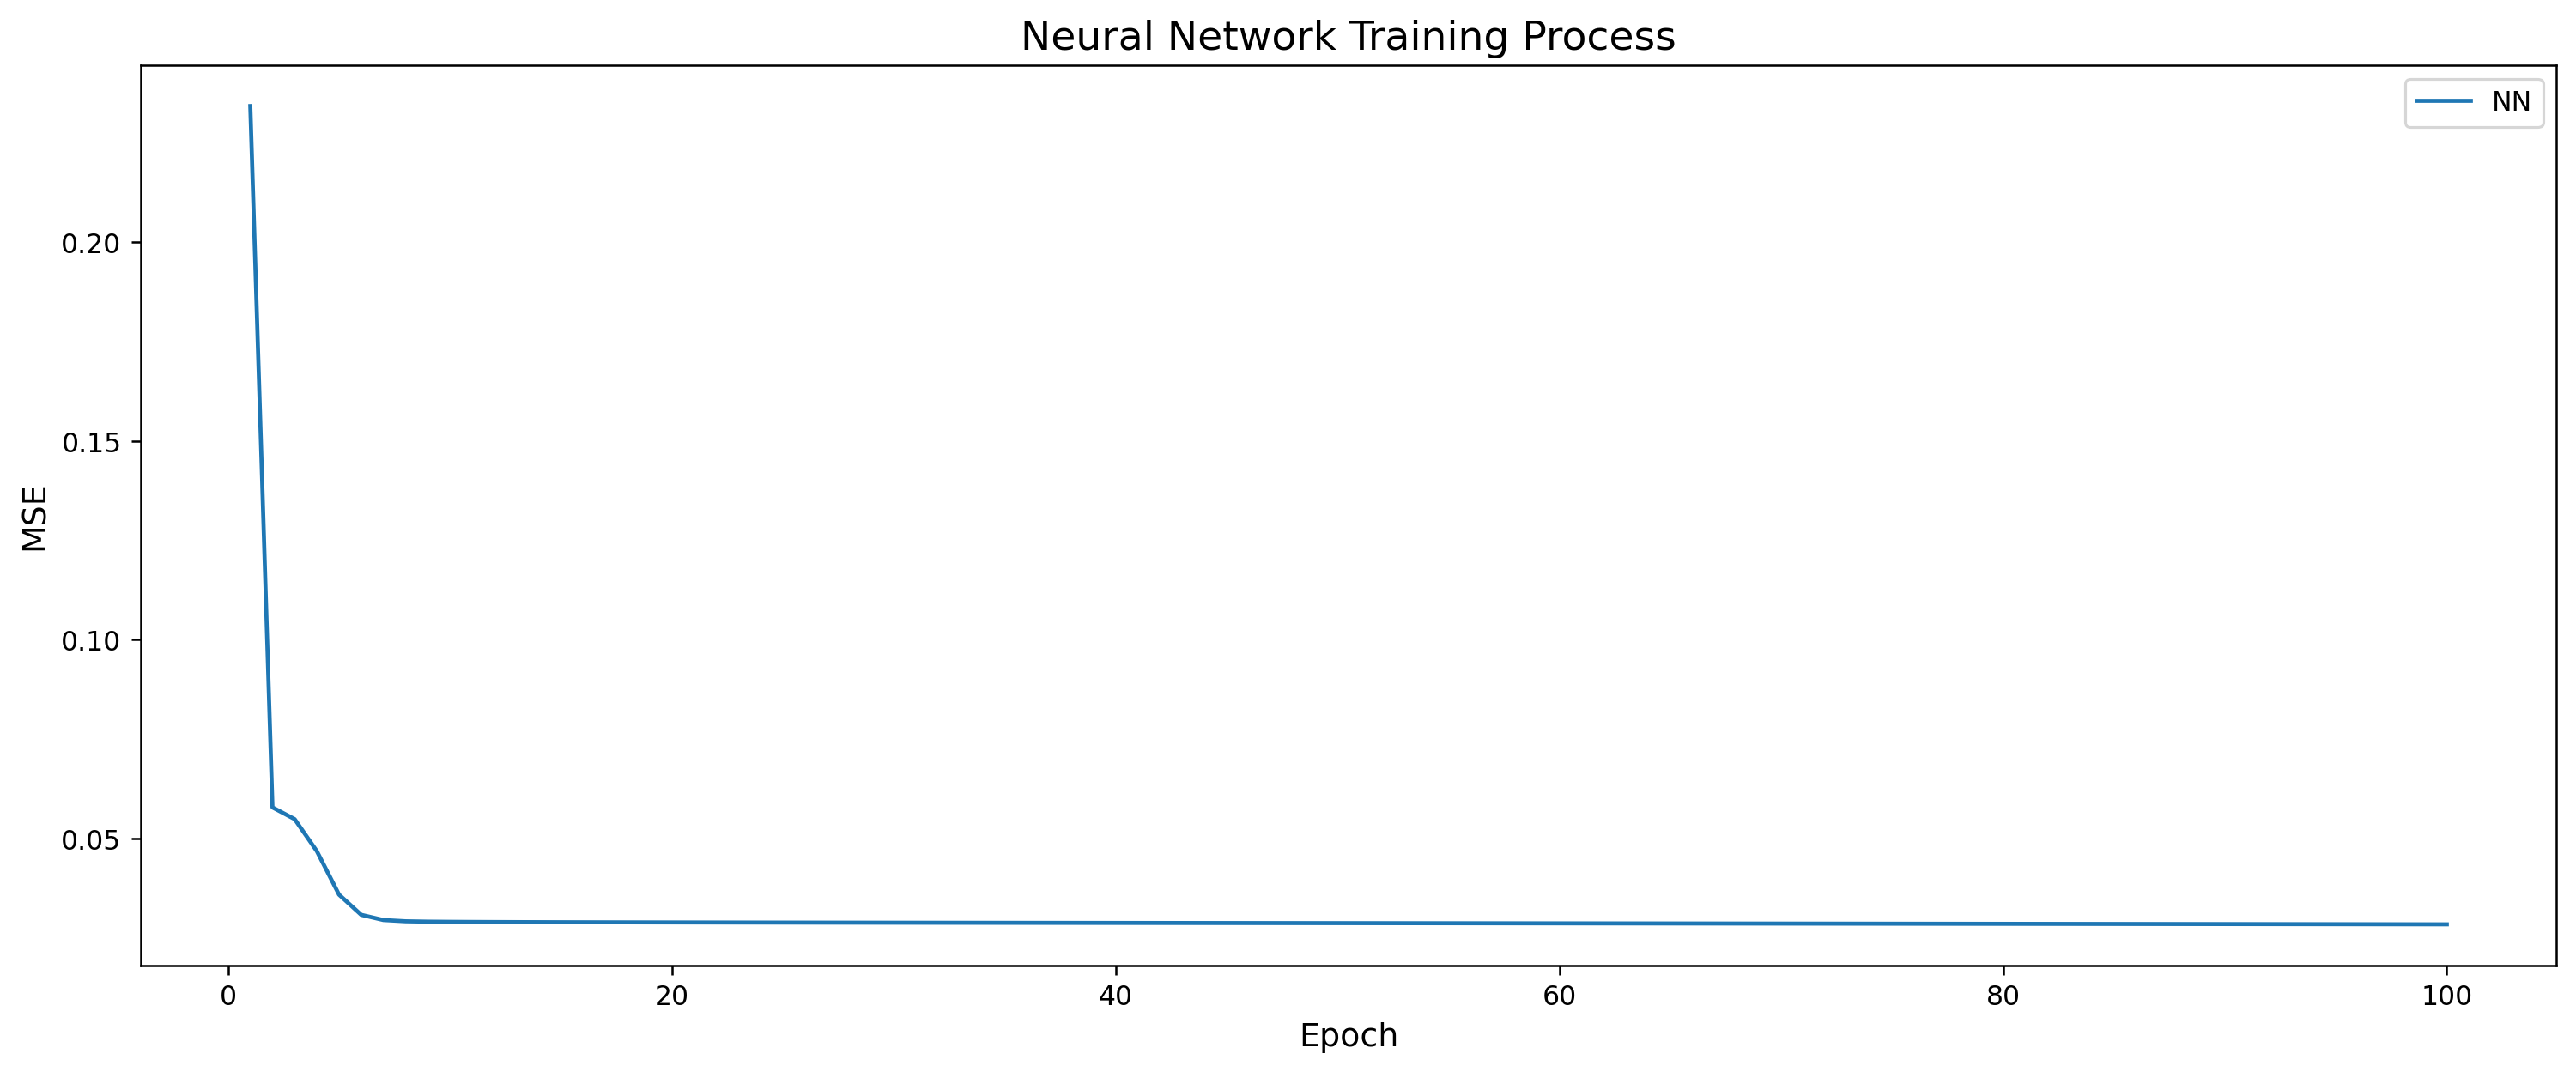

In [17]:
plt.rcParams['figure.dpi'] = 227
plt.rcParams['figure.figsize'] = (16, 6)
plt.style.use('seaborn-whitegrid')
plt.plot(history)
plt.title('Neural Network Training Process', fontSize=15)
plt.xlabel('Epoch', fontSize=12)
plt.ylabel('MSE', fontSize=12)
plt.show()